In [1]:
import pandas as pd
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

data = pd.read_csv("data_grupp_13.csv")
print(data.dtypes)

print(data.head())
data.info()

X = data.drop(columns=["target"])

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled)

dbscan = DBSCAN(eps=1.0, min_samples=5)

labels = dbscan.fit_predict(X_scaled)

print(labels)
print(pd.Series(labels).value_counts())


resultat = []

for eps in [0.5, 0.75, 1.0, 1.25, 1.5, 2.0]:

    dbscan = DBSCAN(eps=eps, min_samples=5)

    labels = dbscan.fit_predict(X_scaled)

    antal_kluster = len(set(labels) - {-1})
    antal_brus = sum(labels == -1)

    resultat.append({
        "Epsilon": eps,
        "MinPts": 5,
        "Antal kluster": antal_kluster,
        "Antal brus": antal_brus,
        "Andel brus (%)": round(antal_brus / len(labels) * 100, 2)
    })

resultat_data = pd.DataFrame(resultat)

display(resultat_data)

besok_per_manad       float64
snittorder_kr         float64
tid_pa_sajt_sek       float64
returgrad             float64
kundtjanst_arenden    float64
rabattkod_andel       float64
target                    str
dtype: object
   besok_per_manad  snittorder_kr  tid_pa_sajt_sek  returgrad  \
0             11.9         1690.0            261.0       0.36   
1             16.5         2993.0            770.0       0.10   
2             17.7          536.0            102.0       0.00   
3             10.4         1834.0            355.0       0.04   
4              5.2          942.0            165.0       0.54   

   kundtjanst_arenden  rabattkod_andel          target  
0                 5.3             0.24  Risk_for_churn  
1                 0.0             0.36  Lojal_stamkund  
2                 1.4             0.85      Fyndjagare  
3                 0.2             0.26  Lojal_stamkund  
4                 2.6             0.42  Risk_for_churn  
<class 'pandas.DataFrame'>
RangeIndex: 240 

,Epsilon,MinPts,Antal kluster,Antal brus,Andel brus (%)
0,0.50,5,0,240,100.00
1,0.75,5,7,164,68.33
2,1.00,5,3,28,11.67
3,1.25,5,3,10,4.17
4,1.50,5,1,3,1.25
5,2.00,5,1,3,1.25


In [ ]:
dbscan = DBSCAN(eps=1.0, min_samples=5)

labels = dbscan.fit_predict(X_scaled)

pca = PCA(n_components=2, random_state=42)


X_pca = pca.fit_transform(X_scaled)

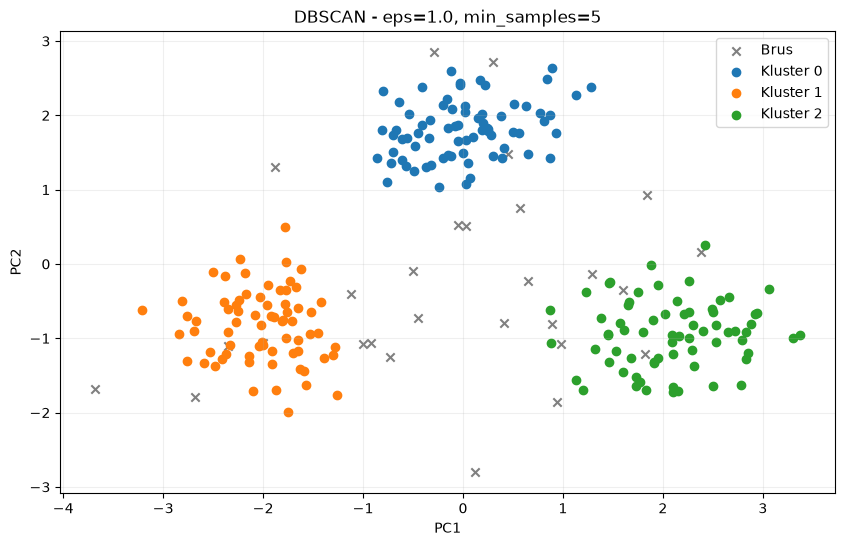

In [3]:
plt.figure(figsize=(10, 6))

for label in sorted(set(labels)):

    mask = labels == label

    if label == -1:
        plt.scatter(
            X_pca[mask, 0],
            X_pca[mask, 1],
            color="gray",
            label="Brus",
            marker="x"
        )
    else:
        plt.scatter(
            X_pca[mask, 0],
            X_pca[mask, 1],
            label=f"Kluster {label}"
        )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("DBSCAN - eps=1.0, min_samples=5")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

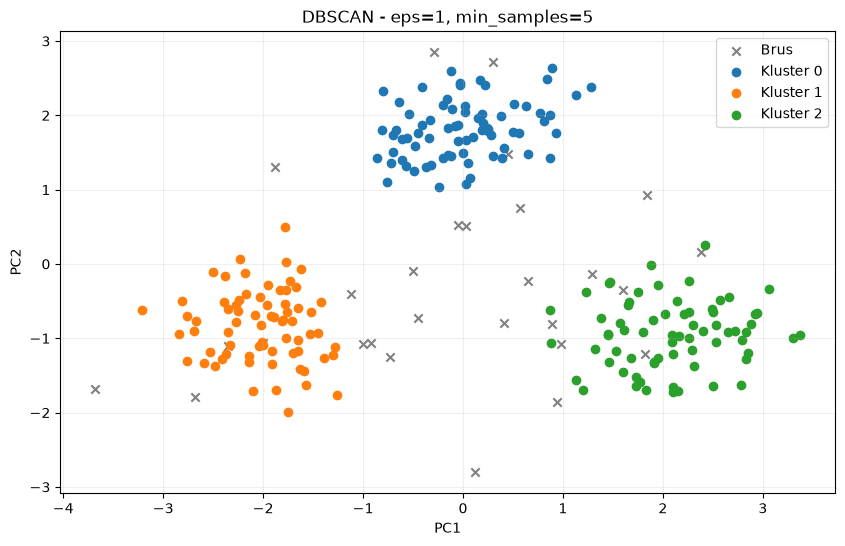

In [4]:
eps = 1
min_pts = 5

dbscan = DBSCAN(eps=eps, min_samples=min_pts)

labels = dbscan.fit_predict(X_scaled)

plt.figure(figsize=(10, 6))

for label in sorted(set(labels)):

    mask = labels == label

    if label == -1:
        plt.scatter(
            X_pca[mask, 0],
            X_pca[mask, 1],
            color="gray",
            label="Brus",
            marker="x"
        )
    else:
        plt.scatter(
            X_pca[mask, 0],
            X_pca[mask, 1],
            label=f"Kluster {label}"
        )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title(f"DBSCAN - eps={eps}, min_samples={min_pts}")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [5]:
from sklearn.cluster import DBSCAN

# DBSCAN med standardinställningar
dbscan = DBSCAN()

# Utför klustring
labels = dbscan.fit_predict(X_scaled)

# Beräkna resultat
antal_kluster = len(set(labels) - {-1})
antal_brus = sum(labels == -1)
andel_brus = antal_brus / len(labels) * 100

# Visa resultat
print("Antal kluster:", antal_kluster)
print("Antal bruspunkter:", antal_brus)
print("Andel brus:", andel_brus, "%")

Antal kluster: 0
Antal bruspunkter: 240
Andel brus: 100.0 %


In [10]:
resultat = []

for min_pts in [3, 5, 7, 10, 15]:

    dbscan = DBSCAN(eps=1.0, min_samples=min_pts)

    labels = dbscan.fit_predict(X_scaled)

    antal_kluster = len(set(labels) - {-1})
    antal_brus = sum(labels == -1)
    andel_brus = antal_brus / len(labels) * 100

    resultat.append({
        "Epsilon": 1.0,
        "MinPts": min_pts,
        "Antal kluster": antal_kluster,
        "Antal brus": antal_brus,
        "Andel brus (%)": round(andel_brus, 2)
    })

resultat_data = pd.DataFrame(resultat)

display(resultat_data)

,Epsilon,MinPts,Antal kluster,Antal brus,Andel brus (%)
0,1.0,3,3,28,11.67
1,1.0,5,3,28,11.67
2,1.0,7,3,38,15.83
3,1.0,10,3,71,29.58
4,1.0,15,3,122,50.83


In [11]:
resultat = []

for eps in [0.5, 0.75, 1.0, 1.25, 1.5, 2.0]:

    for min_pts in [3, 5, 7, 10, 15]:

        dbscan = DBSCAN(eps=eps, min_samples=min_pts)

        labels = dbscan.fit_predict(X_scaled)

        antal_kluster = len(set(labels) - {-1})
        antal_brus = sum(labels == -1)
        andel_brus = antal_brus / len(labels) * 100

        resultat.append({
            "Epsilon": eps,
            "MinPts": min_pts,
            "Antal kluster": antal_kluster,
            "Antal brus": antal_brus,
            "Andel brus (%)": round(andel_brus, 2)
        })

resultat_data = pd.DataFrame(resultat)

display(resultat_data)

,Epsilon,MinPts,Antal kluster,Antal brus,Andel brus (%)
0,0.50,3,2,232,96.67
1,0.50,5,0,240,100.00
2,0.50,7,0,240,100.00
3,0.50,10,0,240,100.00
4,0.50,15,0,240,100.00
5,0.75,3,10,125,52.08
6,0.75,5,7,164,68.33
7,0.75,7,3,194,80.83
8,0.75,10,2,219,91.25
9,0.75,15,0,240,100.00


In [16]:
from sklearn.metrics import silhouette_score

dbscan = DBSCAN(eps=1.0, min_samples=5)

labels_original = dbscan.fit_predict(X_scaled)

mask = labels_original != -1

score = silhouette_score(X_scaled[mask], labels_original[mask])

print("Silhouette före PCA:", score)

Silhouette före PCA: 0.5553880089090449


In [17]:
dbscan = DBSCAN(eps=1.0, min_samples=5)

labels_pca = dbscan.fit_predict(X_pca)

mask = labels_pca != -1

antal_kluster = len(set(labels_pca) - {-1})

if 2 <= antal_kluster < sum(mask):
    score = silhouette_score(
        X_pca[mask], labels_pca[mask]
    )
    print("Silhouette efter PCA:", score)
else:
    print("Silhouette kan inte beräknas")

Silhouette efter PCA: 0.5892720922301496


In [14]:
pca = PCA(n_components=0.90, svd_solver="full")

X_pca = pca.fit_transform(X_scaled)

dbscan = DBSCAN(eps=1.0, min_samples=5)

labels = dbscan.fit_predict(X_pca)

print("Dimensioner före PCA:", X_scaled.shape[1])
print("Dimensioner efter PCA:", X_pca.shape[1])

print("Förklarad varians:",
      pca.explained_variance_ratio_.sum())

Dimensioner före PCA: 6
Dimensioner efter PCA: 4
Förklarad varians: 0.9391985996309891


In [15]:
dbscan = DBSCAN(eps=1.0, min_samples=5)

labels_original = dbscan.fit_predict(X_scaled)

pca_2d = PCA(n_components=2, random_state=42)

X_pca_2d = pca_2d.fit_transform(X_scaled)

In [18]:
print("Före PCA")
print("Antal kluster:", len(set(labels_original) - {-1}))
print("Antal brus:", sum(labels_original == -1))
print("Andel brus:", sum(labels_original == -1) / len(labels_original) * 100)

print("\nEfter PCA")
print("Antal kluster:", len(set(labels_pca) - {-1}))
print("Antal brus:", sum(labels_pca == -1))
print("Andel brus:", sum(labels_pca == -1) / len(labels_pca) * 100)

Före PCA
Antal kluster: 3
Antal brus: 28
Andel brus: 11.666666666666666

Efter PCA
Antal kluster: 3
Antal brus: 12
Andel brus: 5.0
